### Teorema Central Do Limite 

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


In [3]:
N = 500
media = 0.5
variancia = 1/12
z = []
amostra = []

for i in range(N):
    U = np.random.uniform(0,1 , size = N)
    media_amostral = np.mean(U)
    amostra.append(media_amostral)
for x in amostra:
    normal = ((N**0.5)*(x-media))/variancia**0.5
    z.append(normal)


(array([ 11.,  16.,  51., 102.,  93., 116.,  59.,  39.,   8.,   5.]),
 array([-2.79144222, -2.1932451 , -1.59504797, -0.99685085, -0.39865373,
         0.19954339,  0.79774051,  1.39593764,  1.99413476,  2.59233188,
         3.190529  ]),
 <BarContainer object of 10 artists>)

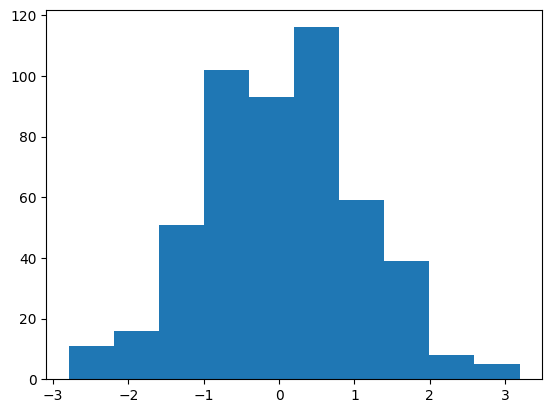

In [4]:
plt.hist(z)

### Bernoulli

In [5]:
p = 0.5
desvio = 0.5
z = []
pull = []
for j in range(N):
    amostra = []
    U = np.random.uniform(0,1,N)
    for i in range(N):
        if U[i] < p:
            amostra.append(1)
        else:
            amostra.append(0)
    media = np.mean(amostra)
    pull.append(media)
for x in pull:
    normal = ((N**0.5)*(x - p))/desvio
    z.append(normal)


(array([  2.,   8.,  16.,  59., 115., 123.,  98.,  58.,  18.,   3.]),
 array([-3.48826604, -2.84427847, -2.20029089, -1.55630331, -0.91231573,
        -0.26832816,  0.37565942,  1.019647  ,  1.66363458,  2.30762215,
         2.95160973]),
 <BarContainer object of 10 artists>)

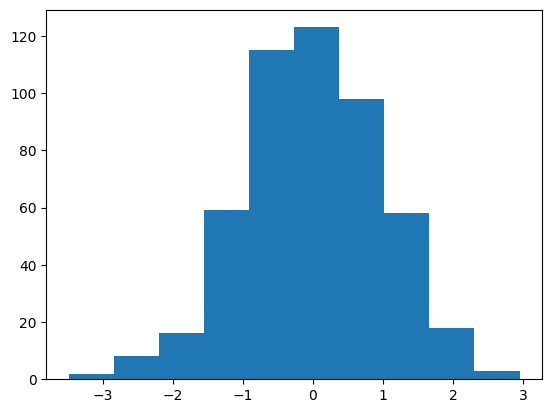

In [6]:
plt.hist(z)

### Geometrica

(array([  6.,  23.,  79., 183., 287., 221., 130.,  48.,  18.,   5.]),
 array([-3.22516149, -2.55155182, -1.87794214, -1.20433246, -0.53072278,
         0.1428869 ,  0.81649658,  1.49010626,  2.16371594,  2.83732562,
         3.5109353 ]),
 <BarContainer object of 10 artists>)

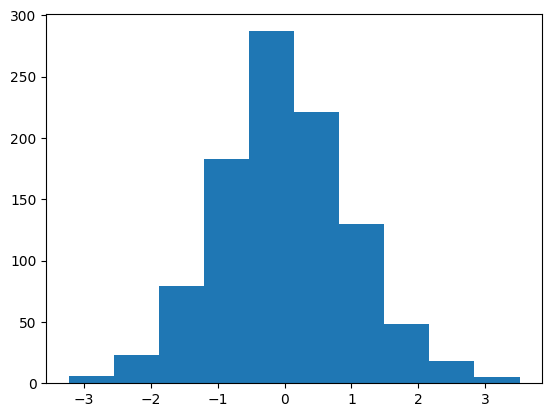

In [7]:

p = 0.5
n = 300
n_repeticoes = 1000

mu = 1 / p
desvio_padrão = ((1 - p) / p**2)**0.5

def gerar_geometrica(p, size):
    U = np.random.uniform(0, 1, size=size)
    X = np.ceil(np.log(1 - U) / np.log(1 - p))
    return X
amostras = gerar_geometrica(p, size=(n_repeticoes, n))

medias = amostras.mean(axis=1)
normal = ((n**0.5)*(medias - (mu)))/desvio_padrão
plt.hist(normal)


### Poisson

In [53]:

lam = 4
desvio = np.sqrt(lam)
media = []

for k in range(N):

    amostra = []

    for j in range(N):

        i = 0
        p = np.exp(-lam)

        U = np.random.uniform(0, 1)

        f = p

        while U > f:
            i = i + 1
            p = lam / i * p
            f = f + p

        amostra.append(i)

    media.append(np.mean(amostra))


z = []

for x in media:

    normal = ((N**0.5) * (x - lam)) / desvio

    z.append(normal)

(array([  4.,  14.,  33.,  68., 113., 112.,  84.,  46.,  16.,  10.]),
 array([-3.08577381, -2.48874366, -1.89171351, -1.29468336, -0.69765321,
        -0.10062306,  0.49640709,  1.09343724,  1.69046739,  2.28749754,
         2.88452769]),
 <BarContainer object of 10 artists>)

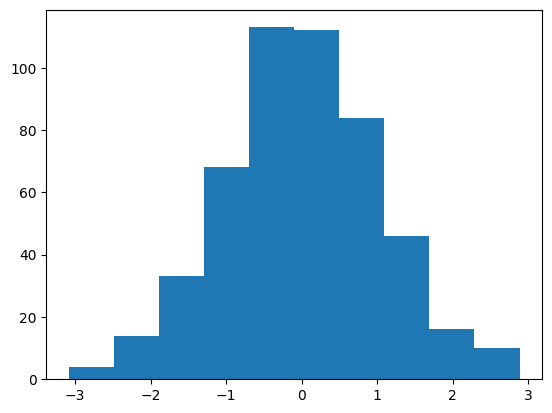

In [54]:
plt.hist(z)

(array([  5.,  28.,  54., 107., 104.,  98.,  61.,  26.,  14.,   3.]),
 array([-2.72162212, -2.13469015, -1.54775817, -0.9608262 , -0.37389422,
         0.21303776,  0.79996973,  1.38690171,  1.97383368,  2.56076566,
         3.14769763]),
 <BarContainer object of 10 artists>)

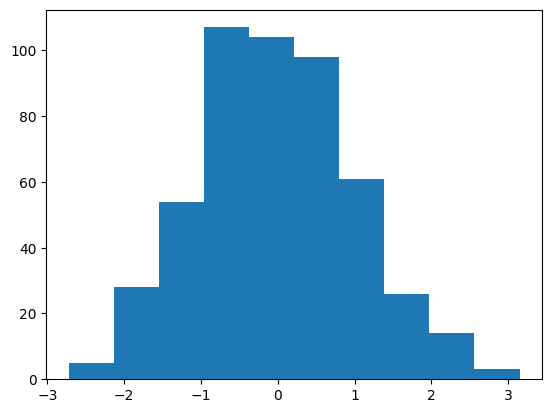

In [59]:
a = np.random.normal(0,1, size = N)
plt.hist(a)

# Aproximação da binomial para a poisson

In [69]:
lam = 4
M = 3000
valor_n = [30, 60, 76, 100]

amostras = []

for n in valor_n:

    p = lam / n
    amostra = []

    for j in range(M):

        x = 0

        for i in range(n):

            U = np.random.uniform(0, 1)

            if U < p:
                x = x + 1

        amostra.append(x)

    amostras.append(amostra)


(array([[2.230e+02, 4.160e+02, 1.265e+03, 4.930e+02, 3.260e+02, 2.380e+02,
         2.300e+01, 1.600e+01, 0.000e+00, 0.000e+00],
        [2.660e+02, 4.500e+02, 1.180e+03, 5.030e+02, 3.140e+02, 2.470e+02,
         2.400e+01, 1.300e+01, 3.000e+00, 0.000e+00],
        [2.480e+02, 4.140e+02, 1.208e+03, 4.610e+02, 3.240e+02, 2.840e+02,
         4.300e+01, 1.500e+01, 1.000e+00, 2.000e+00],
        [2.710e+02, 4.250e+02, 1.215e+03, 4.540e+02, 3.040e+02, 2.680e+02,
         4.000e+01, 2.100e+01, 0.000e+00, 2.000e+00]]),
 array([ 0. ,  1.4,  2.8,  4.2,  5.6,  7. ,  8.4,  9.8, 11.2, 12.6, 14. ]),
 <a list of 4 BarContainer objects>)

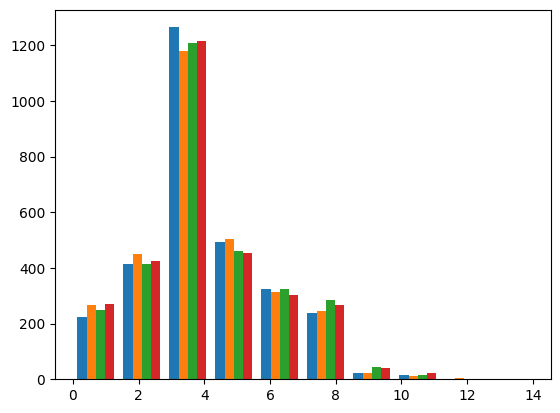

In [70]:
plt.hist(amostras)

(array([ 48.,  70., 117., 105.,  67.,  48.,  22.,  16.,   5.,   2.]),
 array([ 0. ,  1.1,  2.2,  3.3,  4.4,  5.5,  6.6,  7.7,  8.8,  9.9, 11. ]),
 <BarContainer object of 10 artists>)

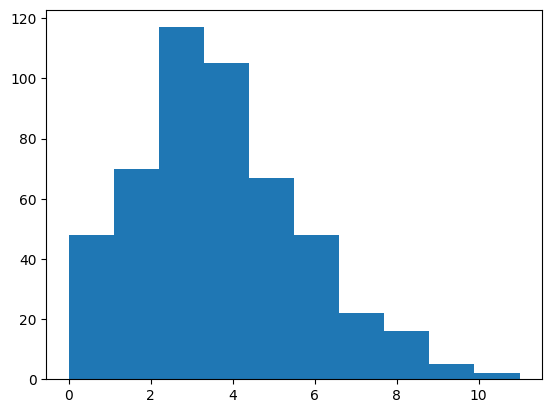

In [67]:
k = np.random.binomial(n, lam/n, size = N)
plt.hist(k)

In [71]:
import time
lam = 4
M = 1000
n = 1000

inicio = time.perf_counter()

lam = 4
desvio = np.sqrt(lam)
media = []

for k in range(N):

    amostra = []

    for j in range(N):

        i = 0
        p = np.exp(-lam)

        U = np.random.uniform(0, 1)

        f = p

        while U > f:
            i = i + 1
            p = lam / i * p
            f = f + p

        amostra.append(i)

    media.append(np.mean(amostra))


z = []

for x in media:

    normal = ((N**0.5) * (x - lam)) / desvio

    z.append(normal)

fim = time.perf_counter()

tempo1 = fim - inicio

inicio = time.perf_counter()
lam = 4
M = 3000
valor_n = [30, 60, 76, 100]

amostras = []

for n in valor_n:

    p = lam / n
    amostra = []

    for j in range(M):

        x = 0

        for i in range(n):

            U = np.random.uniform(0, 1)

            if U < p:
                x = x + 1

        amostra.append(x)

    amostras.append(amostra)

fim = time.perf_counter()

tempo2 = fim - inicio


print("Tempo método 1:", tempo1, "segundos")
print("Tempo método 2:", tempo2, "segundos")

Tempo método 1: 1.7590983000118285 segundos
Tempo método 2: 2.19061699998565 segundos
